In [2]:
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import silhouette_score
import scipy.cluster.hierarchy as sch

import matplotlib.pyplot as plt
import seaborn as sb

from pathlib import Path
from IPython.display import display

from sentence_transformers import SentenceTransformer

In [3]:
data = pd.read_csv('data/E-Commerce_Reviews_for_class.csv')
data.head()

,Clothing ID,Age,Title,Review Text,Rating
0,833,50,More beautiful in person,I bought this in the store and love it. seeing...,4
1,1046,66,Wonderful,This wide leg pant gives the perception of a s...,5
2,945,23,Not for me,I ordered this with another sweater to compare...,4
3,1094,45,"For curvy or tall, not for the waist challenged","The fabric, so diaphanous! so flowy! the patte...",3
4,840,57,Comfortable,A nice rayon peasant shirt - like the sleeve l...,5


In [4]:
data['review_content'] = data.apply(lambda row: f"{row['Title']}. {row['Review Text']}", axis=1)

In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Clothing ID     3000 non-null   int64
 1   Age             3000 non-null   int64
 2   Title           3000 non-null   str  
 3   Review Text     3000 non-null   str  
 4   Rating          3000 non-null   int64
 5   review_content  3000 non-null   str  
dtypes: int64(3), str(3)
memory usage: 2.1 MB


In [6]:
data.review_content.apply(lambda rc: len(rc.split())).describe()

count    3000.000000
mean       64.664333
std        28.621275
min         6.000000
25%        41.000000
50%        63.000000
75%        93.000000
max       118.000000
Name: review_content, dtype: float64

In [7]:
# transformer = SentenceTransformer('all-MiniLM-L12-v2')

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [8]:
# transformer.save_pretrained('models/all-MiniLM-L12-v2')

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [9]:
transformer = SentenceTransformer('models/all-MiniLM-L12-v2', local_files_only=True)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [10]:
review_vectors = transformer.encode(data.review_content.to_numpy())

In [11]:
review_vectors.shape

(3000, 384)

In [12]:
cos_dist = 1 - cosine_similarity(review_vectors, review_vectors)

In [13]:
cos_dist.shape

(3000, 3000)

In [14]:
review_linkage = sch.linkage(cos_dist, method='ward')

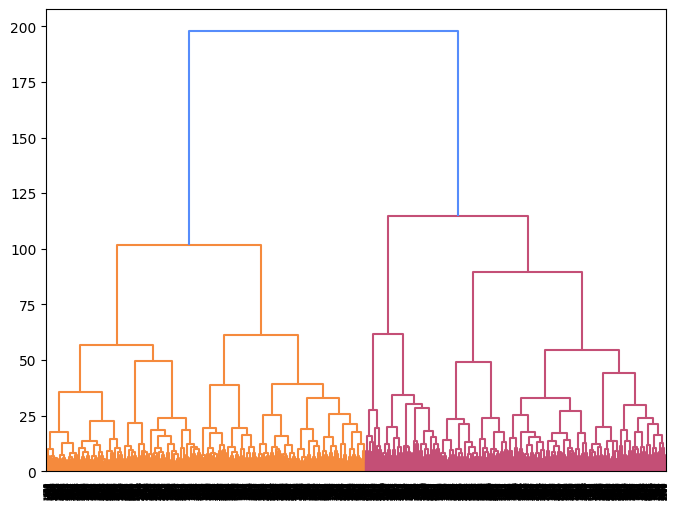

In [15]:
plt.figure(figsize=(8,6))
sch.dendrogram(review_linkage)
plt.show()

In [16]:
k_range = range(2,6)
s_scores = []

cos_dist_clipped = np.clip(cos_dist, a_min=0.0, a_max=None)
for k in k_range:
    k_clusters = sch.fcluster(review_linkage, t=k, criterion='maxclust')
    s_scores.append(silhouette_score(cos_dist_clipped, k_clusters, metric='precomputed'))

In [17]:
for k, score in zip(k_range, s_scores):
    print(f"{k}: {score:.4f}")

2: 0.0543
3: 0.0512
4: 0.0233
5: 0.0437


In [18]:
k_opt = 2
data['clust'] = sch.fcluster(review_linkage, t=k_opt, criterion='maxclust')
data.clust.value_counts()

clust
1    1545
2    1455
Name: count, dtype: int64

In [27]:
def get_cluster_keywords(cluster:int, words_to_remove:list) -> list:
    tfidf_vectoriser = TfidfVectorizer(
        ngram_range=(2,2),
        stop_words='english',
        min_df=0.01,
        max_df=0.95
    )

    cluster_reviews = data.loc[data.clust == cluster, 'review_content']
    reviews_dtm = tfidf_vectoriser.fit_transform(cluster_reviews)
    candidate_kwds = tfidf_vectoriser.get_feature_names_out()

    avg_tfidf_score = np.array(reviews_dtm.mean(axis=1)).flatten()

    candidates_list = [(kwd, score) for kwd, score in zip(candidate_kwds, avg_tfidf_score)]
    candidates_list = sorted(candidates_list, key=lambda item: item[1], reverse=True)
    return [(kwd, score) for kwd, score in candidates_list if kwd not in words_to_remove][:10]

In [ ]:
# get_cluster_keywords(1)

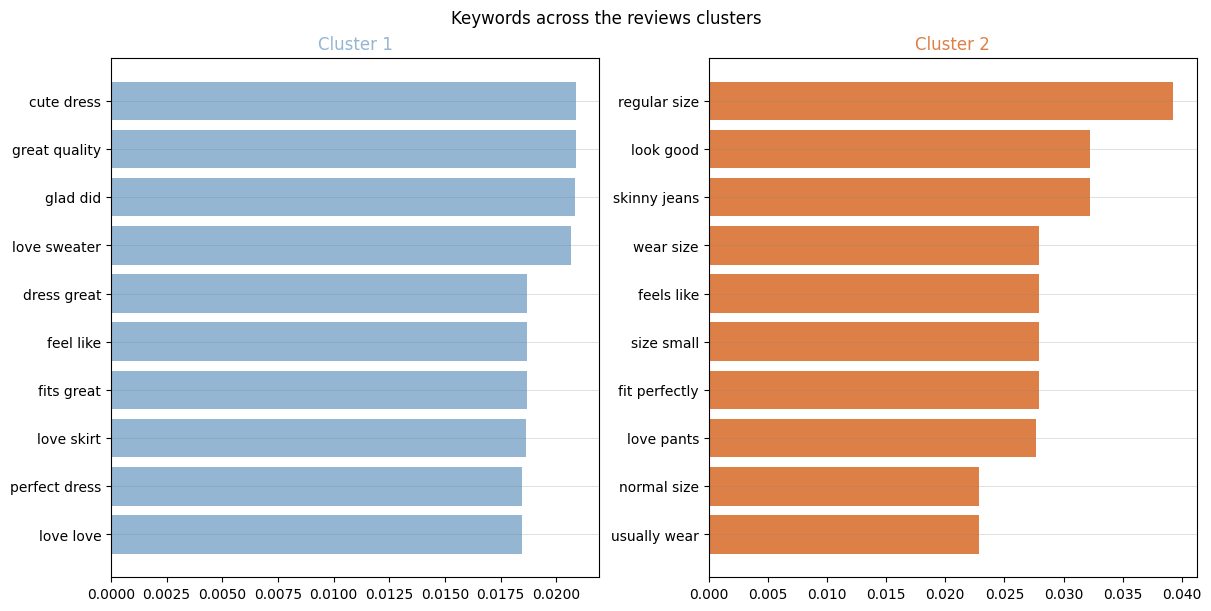

In [29]:
from pypalettes import load_cmap

fig, ax_grid = plt.subplots(nrows=1, ncols=2, figsize=(12, 6), constrained_layout=True)
axes = ax_grid.flatten()

cmap = load_cmap("excel_Median")

n_clust = data['clust'].nunique()
for i in range(n_clust):

    scored_kwds = get_cluster_keywords(i+1, words_to_remove=['fits perfectly', 'great fit'])
    scored_kwds = sorted(scored_kwds, key=lambda item: item[1])
    scores = [s for kw, s in scored_kwds]
    keywords = [kw for kw, s in scored_kwds]

    axes[i].barh(keywords, scores, color=cmap(i))
    axes[i].set_title(f"Cluster {i+1}", color=cmap(i))
    axes[i].grid(visible=True, axis='y', color='gray', alpha=0.35)

# zs slucaj da je kreirano vise plotova nego sto je potrebno za prikaz (npr. grid 2x2, za prikaz 3 klastera)
# axes[n_clust].remove()

fig.suptitle("Keywords across the reviews clusters")

plt.show()